# Classical AI: Local Search and Optimization

> **Who is this for:** a beginner who has finished [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb) and knows high-school maths, or a university student revising local search for an exam or an interview.
>
> **What you will learn**
> - What a **state-space landscape** is: global and local maxima, plateaus, shoulders and ridges (with 1-D and 2-D plots)
> - **Hill climbing** in five flavours: steepest-ascent, sideways moves, first-choice, stochastic and random-restart
> - **Simulated annealing**: temperature schedules and the acceptance probability $e^{\Delta E / T}$
> - **Local beam search** and **stochastic beam search**, and how they relate to beam search in LLM decoding
> - **Genetic algorithms**: encoding, fitness, selection, crossover and mutation
> - Every method applied to **8-Queens / N-Queens** (success rates over many runs) and a **15-city Travelling Salesperson Problem** (tours and cost curves), checked against the exact optimum
> - Short notes on **gradient descent** (local search in continuous spaces) and **tabu search**
>
> **Prerequisites:** [`01_Python/01_basic.ipynb`](../../01_Python/01_basic.ipynb). It helps to have seen uninformed and informed search in the earlier notebooks of this module ([`03_informed_search.ipynb`](03_informed_search.ipynb)), but this notebook stands on its own.
>
> **Time needed:** about 2 hours (the code runs in well under a minute).
>
> **Runs on:** CPU, no API key. Only Python, numpy, pandas and matplotlib.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; it is recommended for BS/MS AI students and for interview prep. You can skip it and still follow the rest of the repo.

## Explained simply

Sometimes you do not need a route to the answer, you just need a *good answer*: a seating plan with no arguments, a short delivery route, a timetable without clashes. **Local search** starts from any complete answer, even a bad one, and keeps making small changes that make it better. It is like straightening a picture on the wall: nudge it a little, step back, keep the nudge if it looks better. Or like tuning a guitar string: turn the peg a little, listen, and keep turning in the direction that sounds better. The danger is getting stuck on an answer that is "the best around here" but not the best overall, like a hiker in fog who climbs the nearest small hill and thinks it is the mountain top. The tricks in this notebook (starting again, sometimes accepting a worse step, keeping several candidates, "breeding" good answers) are all ways of getting unstuck. Training a neural network is the same idea on a giant scale.

**Tiny example.** Four friends sit in a row: A B C D. A and B always argue, and so do C and D. Score = number of arguing pairs sitting next to each other. "A B C D" scores 2 (A-B and C-D are neighbours). Make one small change, swapping B and C: "A C B D" now has neighbours A-C, C-B and B-D, so the score is 0. One local move fixed it.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Hill climbing | keep making the small change that helps most, stop when nothing helps | tweaking a recipe, polishing a delivery route |
| Simulated annealing | sometimes accept a worse step early on, so you do not get stuck | chip layout, factory scheduling |
| Beam search | keep only the best few candidates at every step | how translation models and LLMs can pick their words |

## 0. Why local search?

*In plain words: when only the final answer matters, improve one answer step by step instead of exploring every path.*

The search algorithms in the earlier notebooks (BFS, DFS, A\*) explore **paths**: they remember how they got to each state, and the answer is the path. For many problems the path does not matter at all. Only the **final state** matters:

| Problem | What we want | Does the path matter? |
|---|---|---|
| 8-Queens | a board with 8 non-attacking queens | No |
| Travelling Salesperson (TSP) | the shortest round trip | No, we want the tour itself |
| Timetabling, chip layout, factory scheduling | a good arrangement | No |
| Training a neural network | good weights | No |

**Local search** algorithms keep only **one current state** (or a few) and repeatedly move to a **neighbouring** state. They do not store the search tree.

*Everyday analogy:* you are on a hill in thick fog and want to reach the highest point. You cannot see the map. You can only feel the ground around your feet and step in the best direction. That is hill climbing.

Two big advantages:
1. **Tiny memory**: usually $O(1)$ states, compared with the exponential frontier of BFS.
2. They work on **huge or infinite** (continuous) state spaces where systematic search is hopeless.

The price: they are usually **not complete** (they may fail to find a solution that exists) and **not optimal** (they may return a merely good solution).

Local search usually uses a **complete-state formulation**: every state is a full candidate answer (all 8 queens already on the board, a full tour), and a move changes it slightly.

In [1]:
# Setup: imports used throughout the notebook
import math, random, time, itertools          # standard library
from collections import Counter               # counting queens per row/diagonal
import numpy as np                            # arrays and fast maths
import pandas as pd                           # tables for traces and results
import matplotlib.pyplot as plt               # plots

random.seed(42)                               # make every run reproducible
np.random.seed(42)
plt.rcParams["figure.dpi"] = 100              # crisp but small figures
pd.set_option("display.width", 140)
NOTEBOOK_START = time.time()                  # to report total runtime at the end
print("ready")

ready


## 1. The state-space landscape

*In plain words: picture every possible answer as a point on a hilly map, where height means quality.*

Picture every state laid out along the ground, with its "goodness" as the height. This picture is the **state-space landscape**.

- **Objective function**: the height we want to **maximise** (for example, the number of non-attacking queen pairs).
- **Cost / heuristic function**: the depth we want to **minimise** (for example, the number of *attacking* pairs). Maximising $f$ and minimising $-f$ are the same thing, so the textbook talks about "hill climbing" even when we minimise a cost.

Key terrain features (Russell & Norvig, AIMA 4th ed., Section 4.1):

| Term | Precise meaning | Why it hurts hill climbing |
|---|---|---|
| **Global maximum** | a state with the highest value of all | this is what we want |
| **Local maximum** | higher than every neighbour, but lower than the global maximum | no uphill move exists, so the climber stops |
| **Plateau** (flat local maximum) | a flat area where all neighbours have equal value and there is no way up | no direction looks better; the climber wanders or stops |
| **Shoulder** | a plateau from which an uphill edge *does* exist | the climber may stop before finding the edge |
| **Ridge** | a sequence of local maxima that are not directly connected by single moves | every allowed move goes downhill, even though the ridge itself rises |

```
 value
   ^                         global max
   |                            /\
   |   local max               /  \
   |     /\     plateau  shoulder  \
   |    /  \   ______   _____/      \
   |   /    \_/      \_/             \___
   +--------------------------------------> state
```

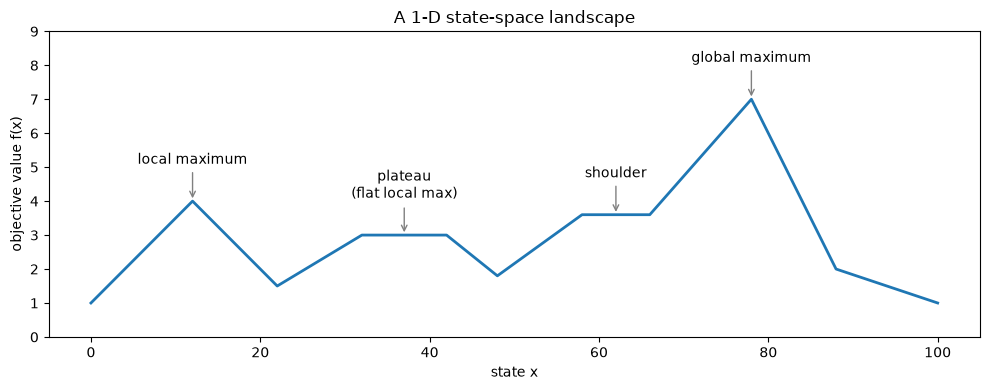

In [2]:
# A 1-D landscape: states are the integers 0..100, the value comes from linear interpolation
control_x = [0, 12, 22, 32, 42, 48, 58, 66, 78, 88, 100]   # x positions of "corners"
control_y = [1, 4, 1.5, 3, 3, 1.8, 3.6, 3.6, 7, 2, 1]      # heights at those corners
states_1d = np.arange(101)                                   # 101 discrete states
value_1d = np.interp(states_1d, control_x, control_y)        # height of every state

def f1(x):
    return value_1d[x]            # objective value of state x (to MAXIMISE)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(states_1d, value_1d, color="tab:blue", lw=2)
labels = {12: "local maximum", 37: "plateau\n(flat local max)", 62: "shoulder", 78: "global maximum"}
for x, text in labels.items():
    ax.annotate(text, xy=(x, f1(x)), xytext=(x, f1(x) + 1.1), ha="center",
                arrowprops=dict(arrowstyle="->", color="gray"))
ax.set_xlabel("state x"); ax.set_ylabel("objective value f(x)")
ax.set_title("A 1-D state-space landscape"); ax.set_ylim(0, 9)
plt.tight_layout(); plt.show()

Now let us release a hill climber at a few starting points. Each state $x$ has two **neighbours**, $x-1$ and $x+1$. **Steepest-ascent hill climbing** moves to the best neighbour, but only if it is *strictly* better than the current state; otherwise it stops.

**Allowing sideways moves** means we also accept a neighbour that is *equal* to the current state, up to a limit of consecutive sideways moves (so we do not loop forever on a flat plateau).

,start,stops at (no sideways),value,stops at (20 sideways),value
0,5,12,4.0,12,4.0
1,28,32,3.0,42,3.0
2,50,58,3.6,78,7.0
3,60,60,3.6,78,7.0
4,85,78,7.0,78,7.0


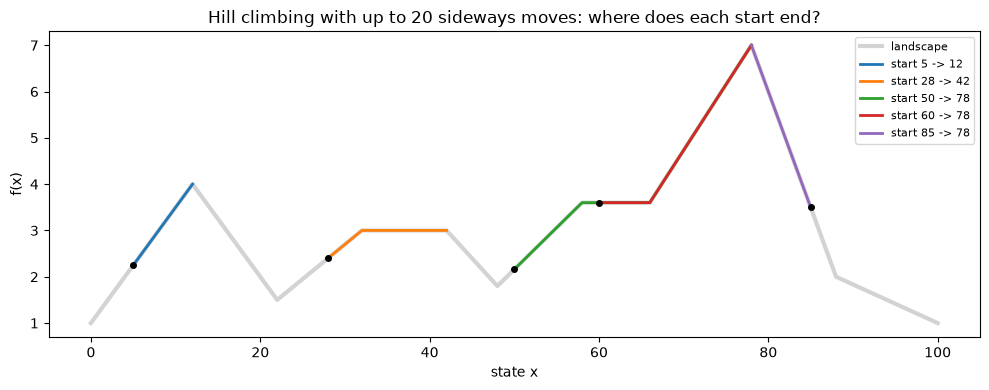

In [3]:
def hill_climb_1d(x, max_sideways=0):
    # Steepest-ascent hill climbing on the 1-D landscape. Returns the path of visited states.
    path = [x]
    sideways_left = max_sideways
    previous = None                                   # avoid stepping straight back on a plateau
    while True:
        nbrs = [n for n in (x + 1, x - 1) if 0 <= n <= 100 and n != previous]
        best = max(nbrs, key=f1)                      # best neighbour (ties: the first, i.e. go right)
        if f1(best) > f1(x):                          # strictly uphill: always take it
            sideways_left = max_sideways              # reset the sideways budget
        elif f1(best) == f1(x) and sideways_left > 0: # flat: allowed only with budget left
            sideways_left -= 1
        else:
            return path                               # no acceptable move: stop here
        previous, x = x, best
        path.append(x)

starts = [5, 28, 50, 60, 85]
rows = []
for s in starts:
    p0 = hill_climb_1d(s, max_sideways=0)
    p1 = hill_climb_1d(s, max_sideways=20)
    rows.append({"start": s, "stops at (no sideways)": p0[-1], "value": f1(p0[-1]),
                 "stops at (20 sideways)": p1[-1], "value ": f1(p1[-1])})
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(states_1d, value_1d, color="lightgray", lw=3, label="landscape")
for s in starts:
    p = hill_climb_1d(s, max_sideways=20)
    ax.plot(p, [f1(x) for x in p], lw=2, label=f"start {s} -> {p[-1]}")
    ax.plot(s, f1(s), "ko", ms=4)
ax.set_xlabel("state x"); ax.set_ylabel("f(x)")
ax.set_title("Hill climbing with up to 20 sideways moves: where does each start end?")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**What just happened?**
- Start 5 climbs to the **local maximum** at x = 12 and stops: both neighbours are lower.
- Start 28 climbs onto the **plateau** (x = 32 to 42). Without sideways moves it stops at its left edge, x = 32. With sideways moves it walks across to x = 42, finds that the next step goes down, and stops anyway. A flat local maximum is a trap either way.
- Starts 50 and 60 end on the **shoulder** (x = 58 to 66). Without sideways moves they are stuck there (the neighbours are equal, not better). With sideways moves they walk to x = 66, find the uphill edge and reach the **global maximum** at x = 78.
- Start 85 is on a slope that leads straight to the global maximum, so it succeeds either way.

(When two neighbours are equally good, this code takes the right-hand one, so a sideways walk keeps going right.)

The lesson: *where you start* decides where hill climbing ends. That is exactly why random restarts work.

Now a 2-D landscape. Here a state is a grid point $(x, y)$ with 4 neighbours (one grid step left, right, down or up). The narrow diagonal ridge is hard: climbing along it would need a diagonal step, which is not an allowed move.

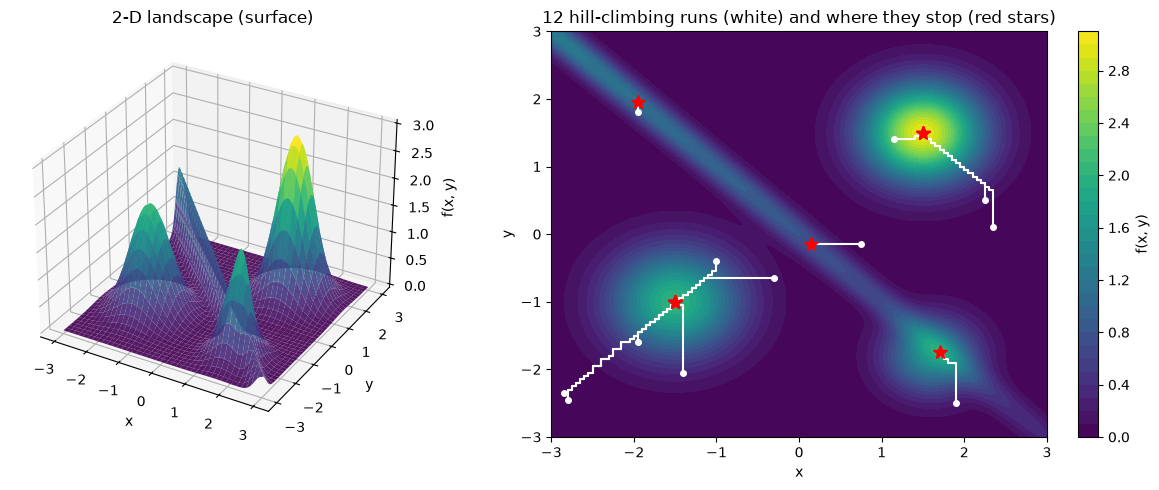

end points and how many runs stopped there: {(1.7, -1.75): 1, (-1.5, -1.0): 6, (-1.95, 1.95): 1, (1.5, 1.5): 3, (0.15, -0.15): 1}


In [4]:
# A 2-D landscape with a global peak, two local peaks and a narrow diagonal ridge
def f2(x, y):
    peak_global = 3.0 * np.exp(-((x - 1.5)**2 + (y - 1.5)**2) / 0.5)
    peak_local1 = 2.0 * np.exp(-((x + 1.5)**2 + (y + 1.0)**2) / 0.6)
    peak_local2 = 1.5 * np.exp(-((x - 1.6)**2 + (y + 1.8)**2) / 0.3)
    ridge = 0.8 * (1 + 0.1 * (y - x)) * np.exp(-((x + y)**2) / 0.08)   # rises towards top-left
    return peak_global + peak_local1 + peak_local2 + ridge

grid = np.linspace(-3, 3, 121)                 # 121 x 121 grid of states, spacing 0.05
X, Y = np.meshgrid(grid, grid)
Z = f2(X, Y)

def hill_climb_2d(i, j):
    # steepest ascent on the grid; (i, j) are grid indices; 4 neighbours: left, right, down, up
    path = [(i, j)]
    while True:
        best, best_val = None, Z[j, i]
        for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            ni, nj = i + di, j + dj
            if 0 <= ni < 121 and 0 <= nj < 121 and Z[nj, ni] > best_val:
                best, best_val = (ni, nj), Z[nj, ni]
        if best is None:
            return path                          # local maximum on the grid
        i, j = best
        path.append(best)

rng2 = np.random.default_rng(3)
fig = plt.figure(figsize=(13, 5))
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
ax3d.plot_surface(X, Y, Z, cmap="viridis", linewidth=0, antialiased=True, alpha=0.9)
ax3d.set_title("2-D landscape (surface)"); ax3d.set_xlabel("x"); ax3d.set_ylabel("y"); ax3d.set_zlabel("f(x, y)")
ax = fig.add_subplot(1, 2, 2)
cs = ax.contourf(X, Y, Z, levels=30, cmap="viridis")
fig.colorbar(cs, ax=ax, label="f(x, y)")
ends = Counter()
for _ in range(12):
    i, j = rng2.integers(0, 121, size=2)
    p = hill_climb_2d(i, j)
    px, py = grid[[a for a, _ in p]], grid[[b for _, b in p]]
    ax.plot(px, py, "w-", lw=1.5); ax.plot(px[0], py[0], "wo", ms=4); ax.plot(px[-1], py[-1], "r*", ms=10)
    ends[(round(float(px[-1]), 2), round(float(py[-1]), 2))] += 1
ax.set_title("12 hill-climbing runs (white) and where they stop (red stars)")
ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()
print("end points and how many runs stopped there:", dict(ends))

**What just happened?** Each white line is one hill-climbing run on the contour map. Runs that start in the basin of the big peak at (1.5, 1.5) find the **global maximum**. Others stop on one of the two **local maxima**. Runs that reach the narrow diagonal **ridge** stop on it: the ridge rises towards the top-left, but every allowed move (left, right, up, down) steps off its crest and goes down, so each point on the ridge is a local maximum for this neighbourhood. The algorithm only ever moves uphill, so it can never cross a valley.

**Complexity of one hill-climbing step:** if a state has $b$ neighbours and evaluating one costs $O(e)$, a steepest-ascent step costs $O(b \cdot e)$ time and $O(1)$ extra space (we only keep the current state and the best neighbour).

## 2. The N-Queens problem as local search

*In plain words: a puzzle where each answer is a full board and a small change moves one queen.*

Place $N$ queens on an $N \times N$ chess board so that no two attack each other (same row, same column or same diagonal).

**Complete-state formulation** (AIMA 4.1.1):
- **State**: one queen in each column, so a state is a tuple `state[c] = row of the queen in column c`. There are $N^N$ states ($8^8 \approx 16.8$ million for $N = 8$).
- **Neighbours**: move one queen to another square *in its own column*. Each state has $N(N-1)$ neighbours ($8 \times 7 = 56$).
- **Heuristic cost** $h$: the number of pairs of queens that attack each other, directly or indirectly. A solution has $h = 0$. The maximum is $\binom{N}{2}$ (28 for $N = 8$).

**Worked example by hand** ($N = 4$, rows numbered 0 to 3 from the top):

```
state = (1, 3, 0, 2)          state = (0, 1, 2, 3)
 . . Q .                       Q . . .
 Q . . .                       . Q . .
 . . . Q                       . . Q .
 . Q . .                       . . . Q
 h = 0 (a solution)            h = 6: all 4 queens on one diagonal, C(4,2) = 6 pairs
```

**Counting $h$ fast.** Two queens in columns $c_1, c_2$ attack each other if they share a row ($r_1 = r_2$), a "\\" diagonal ($r_1 - c_1 = r_2 - c_2$) or a "/" diagonal ($r_1 + c_1 = r_2 + c_2$). If $k$ queens share a line, they form $\binom{k}{2} = k(k-1)/2$ attacking pairs. So we count queens per row and per diagonal: $O(N)$ instead of checking all $O(N^2)$ pairs.

In [5]:
def attacking_pairs(state):
    # h(state): number of attacking queen pairs, in O(N).
    # Walk through the columns; each new queen attacks every EARLIER queen on its row or diagonals.
    n = len(state)
    rows, diag_down, diag_up = [0] * n, [0] * (2 * n), [0] * (2 * n)   # queens seen so far per line
    h = 0
    for c, r in enumerate(state):
        h += rows[r] + diag_down[r - c + n] + diag_up[r + c]          # pairs formed with earlier queens
        rows[r] += 1; diag_down[r - c + n] += 1; diag_up[r + c] += 1
    return h

def attacking_pairs_bruteforce(state):
    # The obvious O(N^2) definition, used only to check the fast version
    n = len(state)
    return sum(1 for a in range(n) for b in range(a + 1, n)
               if state[a] == state[b] or abs(state[a] - state[b]) == b - a)

# Check the fast version against brute force on many random boards of several sizes
check_rng = random.Random(0)
for _ in range(2000):
    n = check_rng.randint(4, 12)
    s = tuple(check_rng.randrange(n) for _ in range(n))
    assert attacking_pairs(s) == attacking_pairs_bruteforce(s)
assert attacking_pairs((1, 3, 0, 2)) == 0 and attacking_pairs((0, 1, 2, 3)) == 6   # the hand examples

# Count all 8-queens solutions by brute force over permutations (one queen per row and column)
solutions_8 = [p for p in itertools.permutations(range(8)) if attacking_pairs(p) == 0]
print("8-queens solutions found by brute force:", len(solutions_8))
assert len(solutions_8) == 92                      # the well-known answer

def neighbours(state):
    # all N(N-1) states reachable by moving one queen within its column
    n = len(state)
    for c in range(n):
        for r in range(n):
            if r != state[c]:
                yield state[:c] + (r,) + state[c + 1:]

def random_neighbour(state, rng):
    # one neighbour chosen uniformly at random
    n = len(state)
    c = rng.randrange(n)
    r = rng.choice([x for x in range(n) if x != state[c]])
    return state[:c] + (r,) + state[c + 1:]

def random_board(n, rng):
    return tuple(rng.randrange(n) for _ in range(n))

assert len(list(neighbours(tuple(range(8))))) == 56
print("attacking_pairs verified on 2000 random boards; each 8-queens state has 56 neighbours")

8-queens solutions found by brute force: 92
attacking_pairs verified on 2000 random boards; each 8-queens state has 56 neighbours


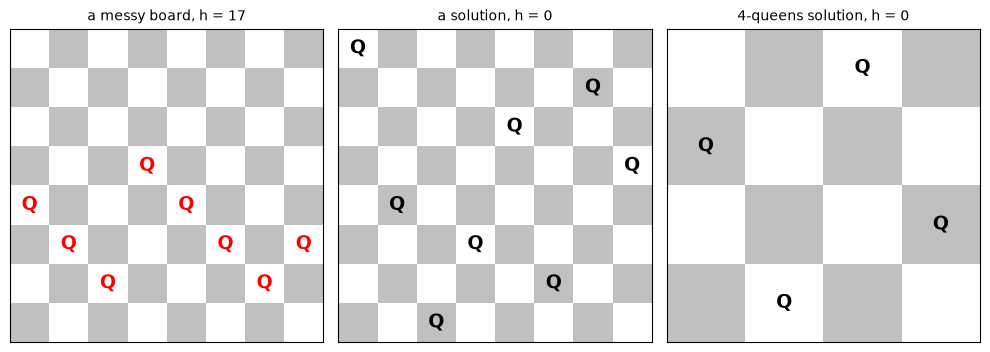

In [6]:
def draw_board(state, ax, title=""):
    # draw a chess board with queens; attacked queens are red
    n = len(state)
    board = np.add.outer(range(n), range(n)) % 2               # checkerboard pattern
    ax.imshow(board, cmap="Greys", alpha=0.25)
    for c, r in enumerate(state):
        attacked = any(state[c2] == r or abs(state[c2] - r) == abs(c2 - c)
                       for c2 in range(n) if c2 != c)
        ax.text(c, r, "Q", ha="center", va="center", fontsize=14 if n <= 10 else 8,
                color="red" if attacked else "black", fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=10)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
example = (4, 5, 6, 3, 4, 5, 6, 5)                           # an arbitrary messy board
draw_board(example, axes[0], f"a messy board, h = {attacking_pairs(example)}")
draw_board(solutions_8[0], axes[1], f"a solution, h = {attacking_pairs(solutions_8[0])}")
draw_board((1, 3, 0, 2), axes[2], "4-queens solution, h = 0")
plt.tight_layout(); plt.show()

## 3. Hill climbing and its variants

*In plain words: always step to a better neighbour; the variants differ in which neighbour and what to do when stuck.*

All variants share one idea: *look at neighbours, move to a better one, repeat*. They differ in **which** neighbour they pick and **what they do when stuck**.

| Variant | Rule | Strength | Weakness |
|---|---|---|---|
| **Steepest-ascent** | evaluate all neighbours, move to the best if it is strictly better | makes the biggest improvement per step | stuck at local maxima, plateaus and ridges; evaluates every neighbour |
| **Sideways moves** | as above, but also accept an equal neighbour, up to a limit of consecutive sideways moves | escapes shoulders | can still wander on true plateaus; uses more steps |
| **First-choice** | generate random neighbours until one is better, take it | fast when there are many neighbours | same traps as steepest-ascent |
| **Stochastic** | pick at random among the *uphill* neighbours (here: probability proportional to the improvement) | more varied paths | usually slower to converge |
| **Random-restart** | run hill climbing from new random states until one succeeds | complete *with probability approaching 1* | many runs if success probability $p$ is small (expected $1/p$ runs) |

Below, everything is written as **minimising the cost $h$** (number of attacking pairs), which is the same as maximising $-h$.

In [7]:
def steepest_ascent(start, cost, neighbours, rng, max_sideways=0, max_steps=10_000):
    # Steepest-ascent hill climbing (written as descent on cost). Returns a result dict.
    current, h = start, cost(start)
    trace = [h]                                    # cost after every step
    sideways_left = max_sideways
    for _ in range(max_steps):
        if h == 0:                                 # goal: no attacking pairs
            break
        scored = [(cost(s), s) for s in neighbours(current)]
        best_h = min(c for c, _ in scored)
        if best_h > h:                             # every neighbour is worse: local minimum
            break
        if best_h == h:                            # only equal neighbours: plateau or shoulder
            if sideways_left == 0:
                break
            sideways_left -= 1
        else:
            sideways_left = max_sideways           # real progress resets the sideways budget
        best_states = [s for c, s in scored if c == best_h]
        current, h = rng.choice(best_states), best_h   # break ties at random (AIMA)
        trace.append(h)
    return {"state": current, "cost": h, "steps": len(trace) - 1, "trace": trace}

def first_choice(start, cost, random_neighbour, rng, max_tries=500, max_steps=10_000):
    # First-choice hill climbing: take the first random neighbour that is strictly better
    current, h = start, cost(start)
    trace = [h]
    for _ in range(max_steps):
        if h == 0:
            break
        for _ in range(max_tries):
            nxt = random_neighbour(current, rng)
            if cost(nxt) < h:
                current, h = nxt, cost(nxt)
                trace.append(h)
                break
        else:                                      # no better neighbour found in max_tries tries
            break
    return {"state": current, "cost": h, "steps": len(trace) - 1, "trace": trace}

def stochastic_hc(start, cost, neighbours, rng, max_steps=10_000):
    # Stochastic hill climbing: choose among uphill moves, weighted by how much they improve
    current, h = start, cost(start)
    trace = [h]
    for _ in range(max_steps):
        if h == 0:
            break
        uphill = [(h - c, s) for s in neighbours(current) if (c := cost(s)) < h]
        if not uphill:
            break
        weights = [gain for gain, _ in uphill]
        _, current = rng.choices(uphill, weights=weights, k=1)[0]
        h = cost(current)
        trace.append(h)
    return {"state": current, "cost": h, "steps": len(trace) - 1, "trace": trace}

def random_restart(n, rng, max_sideways=0, max_restarts=1000):
    # Random-restart hill climbing: repeat steepest ascent from fresh random boards until success
    total_steps = 0
    for restart in range(max_restarts):
        r = steepest_ascent(random_board(n, rng), attacking_pairs, neighbours, rng, max_sideways)
        total_steps += r["steps"]
        if r["cost"] == 0:
            return {"state": r["state"], "cost": 0, "steps": total_steps, "restarts": restart}
    return {"state": r["state"], "cost": r["cost"], "steps": total_steps, "restarts": max_restarts}

# One traced run of steepest ascent on 8-queens
demo_rng = random.Random(7)
start = random_board(8, demo_rng)
res = steepest_ascent(start, attacking_pairs, neighbours, demo_rng)
print("start:", start, " h =", attacking_pairs(start))
print("end:  ", res["state"], " h =", res["cost"], " after", res["steps"], "steps")
print("cost trace:", res["trace"])

start: (5, 2, 6, 0, 1, 1, 5, 0)  h = 6
end:   (5, 2, 6, 1, 7, 1, 3, 0)  h = 1  after 4 steps
cost trace: [6, 4, 3, 2, 1]


In [8]:
# Step-by-step trace table for one run that succeeds with sideways moves allowed
trace_rng = random.Random(11)
current = random_board(8, trace_rng)
rows = []
for step in range(40):
    h = attacking_pairs(current)
    scored = [(attacking_pairs(s), s) for s in neighbours(current)]
    best_h = min(c for c, _ in scored)
    n_best = sum(1 for c, _ in scored if c == best_h)
    move = "goal" if h == 0 else ("uphill" if best_h < h else ("sideways" if best_h == h else "stuck"))
    rows.append({"step": step, "state": "".join(map(str, current)), "h": h,
                 "best neighbour h": best_h, "# best neighbours": n_best, "move": move})
    if move in ("goal", "stuck"):
        break
    current = trace_rng.choice([s for c, s in scored if c == best_h])
trace_df = pd.DataFrame(rows)
display(trace_df.head(15))
print("rows in trace:", len(trace_df), "| final h:", trace_df['h'].iloc[-1])

,step,state,h,best neighbour h,# best neighbours,move
0,0,77732721,11,6,2,uphill
1,1,74732721,6,4,2,uphill
2,2,74732751,4,3,9,uphill
3,3,44732751,3,2,1,uphill
4,4,44702751,2,2,9,sideways
5,5,44702753,2,1,2,uphill
6,6,14702753,1,0,1,uphill
7,7,14602753,0,1,10,goal


rows in trace: 8 | final h: 0


**What just happened?** Each row is one step. The column "best neighbour h" shows the best cost among the 56 neighbours. When it is lower than `h`, the climber goes **uphill** (in cost terms, downhill). When it is equal, the move is **sideways**: we are on a plateau or shoulder. With unlimited sideways moves (as in this traced loop) the climber eventually finds an exit, or wanders until the step limit.

> ⚠️ **Common mistake:** forgetting to *limit* sideways moves. On a flat local maximum the algorithm would then loop forever. AIMA uses a limit of 100 consecutive sideways moves.

Now let us measure each variant over many random 8-queens boards.

In [9]:
def run_many(name, solver, runs, seed):
    # Run a solver on `runs` random 8-queens boards; collect success, steps and time
    rng = random.Random(seed)
    out = []
    for _ in range(runs):
        t0 = time.perf_counter()
        r = solver(rng)
        out.append({"algorithm": name, "success": r["cost"] == 0, "steps": r["steps"],
                    "ms": 1000 * (time.perf_counter() - t0)})
        if r["cost"] == 0:
            assert attacking_pairs(r["state"]) == 0      # every claimed solution is really valid
    return out

RUNS = 200
hc_results = []
hc_results += run_many("steepest-ascent", lambda rng: steepest_ascent(
    random_board(8, rng), attacking_pairs, neighbours, rng), RUNS, 1)
hc_results += run_many("steepest + 100 sideways", lambda rng: steepest_ascent(
    random_board(8, rng), attacking_pairs, neighbours, rng, max_sideways=100), RUNS, 2)
hc_results += run_many("first-choice", lambda rng: first_choice(
    random_board(8, rng), attacking_pairs, random_neighbour, rng), RUNS, 3)
hc_results += run_many("stochastic", lambda rng: stochastic_hc(
    random_board(8, rng), attacking_pairs, neighbours, rng), RUNS, 4)
hc_results += run_many("random-restart", lambda rng: random_restart(8, rng), RUNS, 5)
hc_results += run_many("random-restart + 100 sideways", lambda rng: random_restart(8, rng, 100), RUNS, 6)

hc_df = pd.DataFrame(hc_results)
def summarise(df):
    g = df.groupby("algorithm", sort=False)
    return pd.DataFrame({
        "runs": g.size(),
        "success rate %": (100 * g["success"].mean()).round(1),
        "mean steps (success)": g.apply(lambda d: d.loc[d.success, "steps"].mean(), include_groups=False).round(1),
        "mean steps (failure)": g.apply(lambda d: d.loc[~d.success, "steps"].mean(), include_groups=False).round(1),
        "mean ms per run": g["ms"].mean().round(2),
    })
hc_table = summarise(hc_df)
display(hc_table)

,runs,success rate %,mean steps (success),mean steps (failure),mean ms per run
algorithm,,,,,
steepest-ascent,200,16.5,4.2,3.1,1.75
steepest + 100 sideways,200,95.5,19.2,48.7,8.93
first-choice,200,15.0,5.7,4.9,3.80
stochastic,200,12.0,5.8,4.3,2.27
random-restart,200,100.0,22.0,NaN,10.42
random-restart + 100 sideways,200,100.0,23.7,NaN,7.26


**What just happened?** Compare with the classic numbers in AIMA (Section 4.1.1): steepest-ascent hill climbing solves about **14%** of random 8-queens boards, taking about 4 steps when it succeeds and 3 when it gets stuck. Allowing up to 100 sideways moves raises the success rate to about **94%**, at the price of roughly 21 steps per success and 64 per failure. Our 200 runs give **16.5%** (about 4.2 steps on success, 3.1 on failure) and **95.5%** with sideways moves: close to the textbook figures (they vary a little with the random sample). First-choice and stochastic hill climbing are no better than steepest-ascent here (15% and 12%): they fall into the same local minima, just by different routes.

**Random-restart hill climbing** always succeeded here. If one run succeeds with probability $p$, the number of runs needed is geometric with mean $1/p$; with $p \approx 0.14$ that is about 7 runs. Each run is cheap, so this is fast in practice.

> 🎓 **Exam / interview tip:** "Is hill climbing complete?" No. Plain hill climbing can get stuck. **Random-restart** hill climbing is complete *with probability approaching 1* (if a solution exists, the chance that no restart finds it shrinks to 0 as restarts increase), because eventually a random start lands in a goal's basin.

## 4. Simulated annealing

*In plain words: allow some bad moves early (when "hot") and fewer and fewer as things "cool down".*

Hill climbing never goes downhill, so it gets stuck. A pure random walk goes anywhere, so it is complete but hopelessly slow. **Simulated annealing** (Kirkpatrick, Gelatt and Vecchi, 1983) mixes the two.

*Analogy:* in metallurgy, **annealing** means heating metal and cooling it slowly so the atoms settle into a low-energy crystal. Cool too fast and you lock in defects (local minima).

**Algorithm** (maximising a value $V$; AIMA Figure 4.5):
1. Pick a **random** neighbour `next`.
2. Let $\Delta E = V(\text{next}) - V(\text{current})$.
3. If $\Delta E > 0$ (an improvement), always move.
4. Otherwise move with probability $\boxed{P(\text{accept}) = e^{\Delta E / T}}$, which is between 0 and 1 because $\Delta E \le 0$.
5. Lower the **temperature** $T$ according to a **schedule**, and repeat.

**Worked example by hand** ($\Delta E = -2$, meaning the move makes things 2 units worse):

| $T$ | $e^{-2/T}$ | meaning |
|---|---|---|
| 10 | $e^{-0.2} \approx 0.82$ | hot: bad moves are usually accepted |
| 1 | $e^{-2} \approx 0.14$ | warm: sometimes |
| 0.1 | $e^{-20} \approx 2 \times 10^{-9}$ | cold: practically never, so it behaves like hill climbing |

So at high temperature the search explores freely; as $T \to 0$ it turns into first-choice hill climbing. Bigger drops (more negative $\Delta E$) are always less likely to be accepted than small ones.

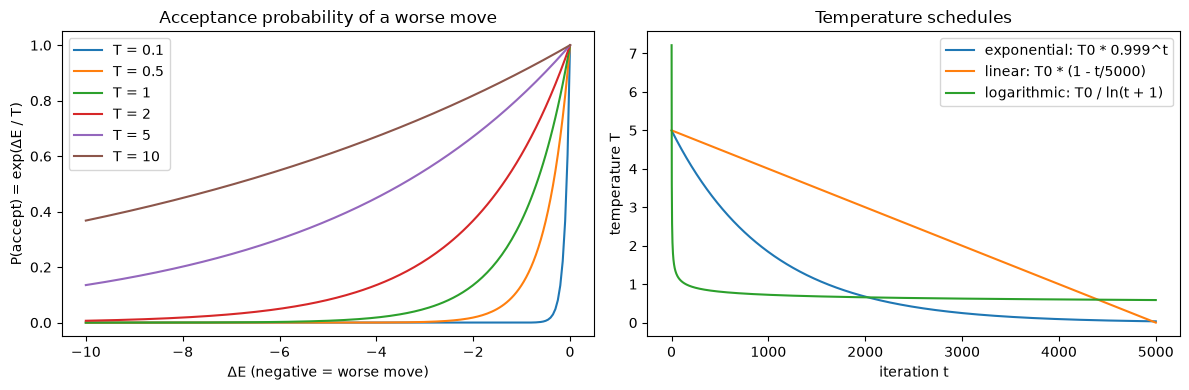

T =   10: P(accept a move with ΔE = -2) = 0.819
T =    1: P(accept a move with ΔE = -2) = 0.135
T =  0.1: P(accept a move with ΔE = -2) = 2.06e-09


In [10]:
# Plot 1: acceptance probability as a function of how bad the move is, for several temperatures
dE = np.linspace(-10, 0, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for T in [0.1, 0.5, 1, 2, 5, 10]:
    axes[0].plot(dE, np.exp(dE / T), label=f"T = {T}")
axes[0].set_xlabel("ΔE (negative = worse move)"); axes[0].set_ylabel("P(accept) = exp(ΔE / T)")
axes[0].set_title("Acceptance probability of a worse move"); axes[0].legend()

# Plot 2: three common temperature schedules
t = np.arange(1, 5001)
T0 = 5.0
schedules = {
    "exponential: T0 * 0.999^t": T0 * 0.999 ** t,
    "linear: T0 * (1 - t/5000)": T0 * (1 - t / 5000),
    "logarithmic: T0 / ln(t + 1)": T0 / np.log(t + 1),
}
for name, T in schedules.items():
    axes[1].plot(t, T, label=name)
axes[1].set_xlabel("iteration t"); axes[1].set_ylabel("temperature T")
axes[1].set_title("Temperature schedules"); axes[1].legend()
plt.tight_layout(); plt.show()
for T in (10, 1, 0.1):
    print(f"T = {T:>4}: P(accept a move with ΔE = -2) = {math.exp(-2 / T):.3g}")

**Which schedule?**
- **Exponential (geometric)** cooling $T_t = T_0 \alpha^t$ with $\alpha$ just below 1 (0.95 to 0.9999) is the most common in practice.
- **Linear** cooling reaches $T = 0$ at a fixed time.
- **Logarithmic** cooling $T_t = c / \ln(t + 1)$ comes with a theorem (Geman & Geman, 1984; Hajek, 1988): with a large enough constant $c$, the probability of being at a global optimum tends to 1. But it cools so slowly that it is useless in practice. Theory and practice disagree here, and that is worth remembering for exams.

final h = 0 after 850 steps; solution: (3, 1, 7, 4, 6, 0, 2, 5)


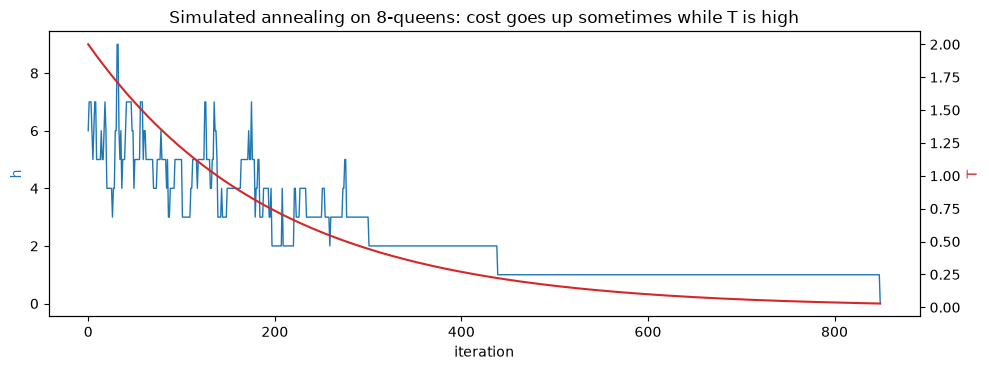

In [11]:
def simulated_annealing(start, cost, random_neighbour, rng, T0=2.0, alpha=0.995, max_steps=20_000, record=False):
    # Simulated annealing for MINIMISING cost. Value V = -cost, so dE = cost(current) - cost(next).
    current, h = start, cost(start)
    trace, temps = [h], [T0]
    T = T0
    for step in range(max_steps):
        if h == 0 or T < 1e-6:                     # solved, or frozen
            break
        nxt = random_neighbour(current, rng)
        h_next = cost(nxt)
        dE = h - h_next                            # > 0 means an improvement
        if dE > 0 or rng.random() < math.exp(dE / T):
            current, h = nxt, h_next               # accept the move
        T *= alpha                                 # exponential cooling
        if record:
            trace.append(h); temps.append(T)
    return {"state": current, "cost": h, "steps": step + 1, "trace": trace, "temps": temps}

sa_rng = random.Random(21)
res = simulated_annealing(random_board(8, sa_rng), attacking_pairs, random_neighbour, sa_rng, record=True)
print("final h =", res["cost"], "after", res["steps"], "steps; solution:", res["state"])
assert res["cost"] == 0 and attacking_pairs(res["state"]) == 0

fig, ax1 = plt.subplots(figsize=(10, 3.8))
ax1.plot(res["trace"], color="tab:blue", lw=1, label="current h (attacking pairs)")
ax1.set_xlabel("iteration"); ax1.set_ylabel("h", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(res["temps"], color="tab:red", lw=1.5, label="temperature T")
ax2.set_ylabel("T", color="tab:red")
ax1.set_title("Simulated annealing on 8-queens: cost goes up sometimes while T is high")
plt.tight_layout(); plt.show()

**What just happened?** The blue cost line is *not* monotonic: early on, while the temperature is high, simulated annealing accepts many worse moves (cost goes up). As $T$ falls, uphill jumps become rare, and the search settles into $h = 0$.

**Complexity:** each iteration costs one neighbour generation and one evaluation, so $O(e)$ time, and the memory is $O(1)$ states. The total number of iterations is set by the schedule.

## 5. Local beam search and stochastic beam search

*In plain words: follow several candidates at once and keep only the best few.*

**Local beam search** keeps **$k$ states** instead of one (AIMA 4.1.3):
1. Start with $k$ random states.
2. Generate **all** successors of **all** $k$ states.
3. If any is a goal, stop. Otherwise keep the **best $k$** of the whole pool, and repeat.

This is *not* the same as $k$ independent random restarts. The $k$ searches **share information**: if one state has excellent successors, they can take over all $k$ slots ("come over here, the grass is greener"). The downside: the $k$ states can quickly crowd into one small region and lose **diversity**.

**Stochastic beam search** fixes this by choosing the $k$ successors **at random**, with a probability that grows with their value (here a Boltzmann weight $e^{-h/\tau}$). Good states are likely to survive, but not guaranteed to. This is like natural selection, and it leads straight to genetic algorithms.

In [12]:
def local_beam_search(n, k, rng, max_steps=100):
    # keep the k best successors of the whole pool at every step
    beam = [random_board(n, rng) for _ in range(k)]
    for step in range(max_steps):
        for s in beam:
            if attacking_pairs(s) == 0:
                return {"state": s, "cost": 0, "steps": step}
        pool = list({nb for s in beam for nb in neighbours(s)})   # all successors, duplicates removed
        pool.sort()                                                # deterministic order before shuffling
        rng.shuffle(pool)                                          # random tie-breaking
        pool.sort(key=attacking_pairs)                             # stable sort: best first
        beam = pool[:k]
    best = min(beam, key=attacking_pairs)
    return {"state": best, "cost": attacking_pairs(best), "steps": max_steps}

def stochastic_beam_search(n, k, rng, tau=1.0, max_steps=200):
    # choose k successors at random with probability proportional to exp(-h / tau)
    beam = [random_board(n, rng) for _ in range(k)]
    for step in range(max_steps):
        for s in beam:
            if attacking_pairs(s) == 0:
                return {"state": s, "cost": 0, "steps": step}
        pool = [nb for s in beam for nb in neighbours(s)]
        hs = np.array([attacking_pairs(p) for p in pool], dtype=float)
        w = np.exp(-(hs - hs.min()) / tau)                         # subtract min for numerical safety
        idx = rng.choices(range(len(pool)), weights=w.tolist(), k=k)
        beam = [pool[i] for i in idx]
    best = min(beam, key=attacking_pairs)
    return {"state": best, "cost": attacking_pairs(best), "steps": max_steps}

r = local_beam_search(8, 10, random.Random(5))
print("local beam (k=10):", r)
r = stochastic_beam_search(8, 10, random.Random(5))
print("stochastic beam (k=10):", r)

local beam (k=10): {'state': (5, 2, 6, 1, 3, 7, 0, 4), 'cost': 0, 'steps': 4}
stochastic beam (k=10): {'state': (3, 7, 4, 2, 0, 6, 1, 5), 'cost': 0, 'steps': 17}


### Link: beam search in LLM decoding

Large language models generate text one **token** at a time. The probability of a whole sentence is the product of the next-token probabilities. Finding the single most likely sentence exactly is hopeless (vocabulary size$^{\text{length}}$ sequences), so decoders use **beam search**: keep the $k$ most probable **partial** sentences, extend each by every possible next token, and keep the $k$ best extensions.

Same idea, one important difference:

| | Local beam search (this notebook) | Beam search in LLM decoding |
|---|---|---|
| A state is | a *complete* candidate (a full board) | a *partial* sequence (a prefix) |
| Score | objective function $h$ | log-probability $\sum_t \log P(w_t \mid w_{<t})$ |
| Type of search | local search | pruned breadth-first (tree) search |
| $k = 1$ gives | steepest-ascent hill climbing | **greedy decoding** |
| Random version | stochastic beam search | sampling-based decoding (temperature, top-k, nucleus) |

Both share the core trick, *keep only the best $k$ at every step*, and both can miss the true optimum. A tiny made-up language model shows this:

In [13]:
# A toy next-token model: probabilities of the next token given the prefix (made-up numbers)
toy_lm = {
    (): {"The": 0.5, "A": 0.4, "One": 0.1},
    ("The",): {"cat": 0.4, "dog": 0.35, "end": 0.25},
    ("A",): {"dog": 0.9, "cat": 0.1},
    ("One",): {"day": 1.0},
    ("The", "cat"): {"sat": 0.5, "ran": 0.5},
    ("The", "dog"): {"ran": 0.6, "sat": 0.4},
    ("The", "end"): {".": 1.0},
    ("A", "dog"): {"barked": 0.6, "sat": 0.4},
    ("A", "cat"): {"sat": 1.0},
    ("One", "day"): {".": 1.0},
}
LENGTH = 3

def beam_decode(k):
    beams = [((), 0.0)]                                      # (prefix, log-probability)
    for _ in range(LENGTH):
        candidates = [(prefix + (tok,), lp + math.log(p))
                      for prefix, lp in beams for tok, p in toy_lm[prefix].items()]
        candidates.sort(key=lambda x: -x[1])                 # most probable first
        beams = candidates[:k]                               # keep the k best prefixes
    return beams[0][0], math.exp(beams[0][1])

def exhaustive_decode():
    best = max((((a, b, c), pa * pb * pc)
               for a, pa in toy_lm[()].items()
               for b, pb in toy_lm[(a,)].items()
               for c, pc in toy_lm[(a, b)].items()), key=lambda x: x[1])
    return best

rows = []
for k in (1, 2, 3):
    seq, p = beam_decode(k)
    rows.append({"method": "greedy (beam k=1)" if k == 1 else f"beam k={k}", "sentence": " ".join(seq), "probability": round(p, 4)})
seq, p = exhaustive_decode()
rows.append({"method": "exhaustive (true best)", "sentence": " ".join(seq), "probability": round(p, 4)})
display(pd.DataFrame(rows))
assert beam_decode(1)[1] <= beam_decode(2)[1] <= exhaustive_decode()[1] + 1e-12

,method,sentence,probability
0,greedy (beam k=1),The cat sat,0.100
1,beam k=2,A dog barked,0.216
2,beam k=3,A dog barked,0.216
3,exhaustive (true best),A dog barked,0.216


**What just happened?** Greedy decoding grabs "The" (the single most likely first word, 0.5) and ends with "The cat sat" (probability $0.5 \times 0.4 \times 0.5 = 0.1$). Beam search with $k = 2$ also keeps "A" alive, and "A dog barked" turns out much better ($0.4 \times 0.9 \times 0.6 = 0.216$). Here $k = 2$ already finds the true best sentence, but in general no fixed $k$ guarantees that. See [`07_NLP/05_language_models_and_generation.ipynb`](../../07_NLP/05_language_models_and_generation.ipynb) for decoding with real models.

## 6. Genetic algorithms

*In plain words: mix pieces of good answers together, add small random changes, keep the fittest, repeat.*

A **genetic algorithm (GA)** (Holland, 1975) is stochastic beam search where successors come from combining **two** parents rather than modifying one.

| GA term | Meaning | For 8-queens |
|---|---|---|
| **Individual / chromosome** | one candidate solution, written as a string | 8 digits, e.g. `24748552` (row of the queen in each column) |
| **Encoding** | how a solution becomes a string | one digit per column |
| **Population** | the current set of individuals | e.g. 100 boards |
| **Fitness** | how good an individual is (higher is better) | non-attacking pairs $= 28 - h$; 28 means solved |
| **Selection** | choose parents, favouring fitter ones | fitness-proportional ("roulette wheel") or **tournament** |
| **Crossover** | combine two parents | cut both strings at a random point and swap the tails |
| **Mutation** | small random change | with small probability, move one queen to a random row |
| **Elitism** | copy the best few unchanged into the next generation | keep the top 2 |

**Worked example by hand** (crossover point after the 3rd digit, as in AIMA Figure 4.6):
```
parent 1:  327|52411         child 1:  327|43552
parent 2:  247|43552   -->   child 2:  247|52411

mutation of child 1 in column 5 (counting from 0): 32743552 -> 32743152 (that queen moves from row 5 to row 1)
```
Crossover is useful when the string has **meaningful blocks**: the left 3 columns of parent 1 may already be a good arrangement and survive intact. **Tournament selection** (pick $t$ individuals at random, keep the fittest) is popular because it does not care about the scale of fitness values.

GA result: (3, 5, 7, 1, 6, 0, 2, 4) h = 0 generations: 42


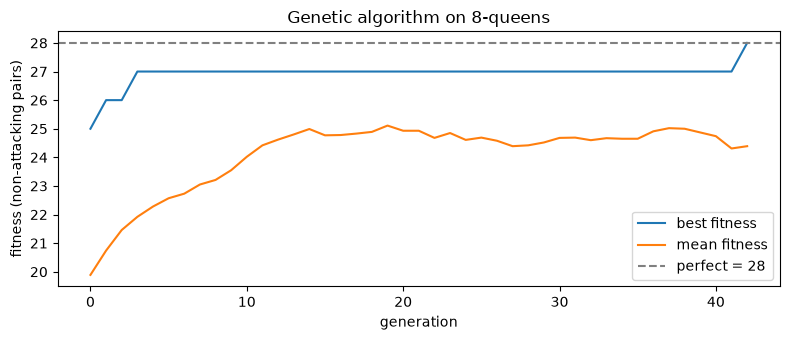

In [14]:
MAX_PAIRS = lambda n: n * (n - 1) // 2

def genetic_algorithm(n, rng, pop_size=100, generations=300, p_mutation=0.8, tournament=3, elite=2, record=False):
    fitness = lambda s: MAX_PAIRS(n) - attacking_pairs(s)          # higher is better
    population = [random_board(n, rng) for _ in range(pop_size)]
    best_hist, mean_hist = [], []
    for gen in range(generations):
        scored = sorted(((fitness(s), s) for s in population), reverse=True)
        if record:
            best_hist.append(scored[0][0]); mean_hist.append(sum(f for f, _ in scored) / pop_size)
        if scored[0][0] == MAX_PAIRS(n):                            # a perfect board
            return {"state": scored[0][1], "cost": 0, "steps": gen, "best": best_hist, "mean": mean_hist}
        def select():                                               # tournament selection
            return max(rng.sample(scored, tournament))[1]
        new_population = [s for _, s in scored[:elite]]             # elitism
        while len(new_population) < pop_size:
            p1, p2 = select(), select()
            cut = rng.randrange(1, n)                               # single-point crossover
            child = p1[:cut] + p2[cut:]
            if rng.random() < p_mutation:                           # mutation: one random gene changes
                c = rng.randrange(n)
                child = child[:c] + (rng.randrange(n),) + child[c + 1:]
            new_population.append(child)
        population = new_population
    best = max(population, key=fitness)
    return {"state": best, "cost": attacking_pairs(best), "steps": generations, "best": best_hist, "mean": mean_hist}

ga = genetic_algorithm(8, random.Random(8), record=True)
print("GA result:", ga["state"], "h =", ga["cost"], "generations:", ga["steps"])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(ga["best"], label="best fitness"); ax.plot(ga["mean"], label="mean fitness")
ax.axhline(28, color="gray", ls="--", label="perfect = 28")
ax.set_xlabel("generation"); ax.set_ylabel("fitness (non-attacking pairs)")
ax.set_title("Genetic algorithm on 8-queens"); ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** The mean fitness of the population climbs quickly as selection keeps fitter boards, and the best individual eventually reaches 28 non-attacking pairs, a valid solution.

**Complexity:** one generation costs $O(P \cdot e)$ for population size $P$ (evaluating everybody) and needs $O(P)$ memory.

> ⚠️ **Common mistake:** setting the mutation rate to 0. Without mutation the population can only recombine genes that already exist; once diversity is lost (every board shares the same digit in some column), the GA can never change it.

### Tabu search (brief)

*In plain words: a hill climber with a short memory that forbids going straight back to where it just was.*

**Tabu search** (Glover, 1986/1989) is steepest-ascent hill climbing that is **allowed to move downhill**, plus a short-term memory that forbids undoing recent moves:
- At every step, move to the best neighbour that is **not tabu**, even if it is worse than the current state.
- After moving queen $c$ away from row $r$, the move "put queen $c$ back on row $r$" becomes **tabu** for the next $L$ steps (the **tabu tenure**).
- **Aspiration criterion:** a tabu move is allowed anyway if it gives the best state seen so far.

The tabu list stops the search from sliding straight back into the local optimum it just left.

In [15]:
def tabu_search(n, rng, tenure=8, max_steps=500):
    current = random_board(n, rng)
    h = attacking_pairs(current)
    best_h = h
    tabu = {}                                        # (column, row) -> step until which it is forbidden
    for step in range(max_steps):
        if h == 0:
            return {"state": current, "cost": 0, "steps": step}
        moves = []
        for c in range(n):
            for r in range(n):
                if r != current[c]:
                    s = current[:c] + (r,) + current[c + 1:]
                    hs = attacking_pairs(s)
                    if tabu.get((c, r), -1) < step or hs < best_h:   # not tabu, or aspiration
                        moves.append((hs, c, r, s))
        best_move_h = min(m[0] for m in moves)
        _, c, r, s = rng.choice([m for m in moves if m[0] == best_move_h])
        tabu[(c, current[c])] = step + tenure        # forbid moving queen c back for `tenure` steps
        current, h = s, best_move_h
        best_h = min(best_h, h)
    return {"state": current, "cost": h, "steps": max_steps}

r = tabu_search(8, random.Random(3))
print("tabu search:", r)
assert r["cost"] == 0 and attacking_pairs(r["state"]) == 0

tabu search: {'state': (3, 1, 6, 4, 0, 7, 5, 2), 'cost': 0, 'steps': 15}


## 7. The big 8-Queens comparison

*In plain words: run every method many times on the same puzzle and count how often each one succeeds.*

Every algorithm gets the same task: solve a random 8-queens board. We repeat each one many times with different random seeds and count how often it succeeds.

In [16]:
RUNS = 200
more = []
more += run_many("simulated annealing", lambda rng: simulated_annealing(
    random_board(8, rng), attacking_pairs, random_neighbour, rng), RUNS, 11)
more += run_many("local beam (k=10)", lambda rng: local_beam_search(8, 10, rng, max_steps=30), RUNS, 12)
more += run_many("stochastic beam (k=10)", lambda rng: stochastic_beam_search(8, 10, rng, max_steps=60), RUNS, 13)
more += run_many("genetic algorithm (P=100)", lambda rng: genetic_algorithm(8, rng, generations=60), RUNS, 14)
more += run_many("tabu search", lambda rng: tabu_search(8, rng, max_steps=200), RUNS, 15)

queens_table = summarise(pd.concat([hc_df, pd.DataFrame(more)]))
queens_table = queens_table.rename(columns={"mean steps (success)": "mean steps/gens (success)",
                                            "mean steps (failure)": "mean steps/gens (failure)"})
display(queens_table)

,runs,success rate %,mean steps/gens (success),mean steps/gens (failure),mean ms per run
algorithm,,,,,
steepest-ascent,200,16.5,4.2,3.1,1.75
steepest + 100 sideways,200,95.5,19.2,48.7,8.93
first-choice,200,15.0,5.7,4.9,3.80
stochastic,200,12.0,5.8,4.3,2.27
random-restart,200,100.0,22.0,NaN,10.42
random-restart + 100 sideways,200,100.0,23.7,NaN,7.26
simulated annealing,200,95.5,749.8,2896.0,6.02
local beam (k=10),200,100.0,3.9,NaN,15.18
stochastic beam (k=10),200,99.5,12.1,60.0,34.71


**How to read the table.** "Steps" means hill-climbing moves for the hill climbers, iterations for simulated annealing, beam steps for beam search and generations for the GA, so the step columns are not directly comparable across rows; the **success rate** and **milliseconds per run** are. Each algorithm also has a budget (for example 60 generations for the GA, 200 steps for tabu search); a "failure" means the budget ran out.

The pattern to remember:
- Plain steepest-ascent fails most of the time, because 8-queens has many local minima.
- Anything that can **escape** local minima (sideways moves, restarts, annealing, tabu memory, a population) succeeds most of the time.
- Local beam search with $k = 10$ beats a single climber because the beam keeps the best of 560 successors per step.
- The GA solved 75% of boards within its 60-generation budget. When it fails, it is usually **premature convergence**: the population becomes copies of one near-solution with $h = 1$ and only lucky mutations can fix it.
- Simulated annealing solved 95.5%. Its failures all stop after about 2,900 iterations, which is when this schedule ($T_0 = 2$, $\alpha = 0.995$) has cooled below $10^{-6}$ and the search is frozen. A slower schedule raises the success rate and the cost.

In [17]:
# How do the methods scale with N? (fewer runs because bigger boards are slower)
scale_rows = []
for n in (8, 12, 16, 20):
    for name, solver, runs in [
        ("random-restart + 100 sideways", lambda rng, n=n: random_restart(n, rng, 100, max_restarts=50), 10),
        ("simulated annealing", lambda rng, n=n: simulated_annealing(random_board(n, rng), attacking_pairs,
                                                                     random_neighbour, rng, T0=2.0, alpha=0.999, max_steps=30_000), 10),
        ("tabu search", lambda rng, n=n: tabu_search(n, rng, tenure=n, max_steps=300), 10),
    ]:
        rng = random.Random(100 + n)
        succ, ms = 0, []
        for _ in range(runs):
            t0 = time.perf_counter()
            r = solver(rng)
            ms.append(1000 * (time.perf_counter() - t0))
            if r["cost"] == 0:
                assert attacking_pairs(r["state"]) == 0
                succ += 1
        scale_rows.append({"N": n, "algorithm": name, "runs": runs, "success rate %": round(100 * succ / runs, 1),
                           "mean ms per run": round(float(np.mean(ms)), 1)})
scale_df = pd.DataFrame(scale_rows).pivot(index="algorithm", columns="N", values=["success rate %", "mean ms per run"])
display(scale_df)

success rate %                      mean ms per run                   
N                                         8      12     16     20              8     12    16     20
algorithm                                                                                           
random-restart + 100 sideways          100.0  100.0  100.0  100.0            11.3  47.5  76.4  197.8
simulated annealing                    100.0  100.0  100.0  100.0            18.9  69.0  65.9  153.3
tabu search                            100.0  100.0  100.0  100.0             7.7  35.5  72.9  183.7

**What just happened?** All three escape strategies keep solving N-Queens as $N$ grows, but the cost per run rises because each step evaluates $N(N-1)$ neighbours (each in $O(N)$), so a step of steepest ascent or tabu search costs $O(N^3)$ in this simple code. The constraint-satisfaction notebook ([`06_constraint_satisfaction.ipynb`](06_constraint_satisfaction.ipynb)) shows **min-conflicts**, a smarter local search that evaluates moves incrementally and solves $N = 1000$ in well under a second.

## 8. A 15-city Travelling Salesperson Problem

*In plain words: find the shortest round trip through 15 cities, and compare each method with the true best trip.*

**TSP:** visit every city exactly once and return to the start, minimising the total distance. There are $(n-1)!/2$ different tours: for $n = 15$ that is $14!/2 \approx 43.6$ billion, far too many to enumerate.

- **State**: a tour, written as a permutation of cities that starts at city 0.
- **Neighbourhood: 2-opt.** Remove two edges and reconnect the tour the other way, which is the same as *reversing* a segment of the tour:
```
before:  ... a -> b -> ... -> c -> d ...        (edges a-b and c-d)
after:   ... a -> c -> ... -> b -> d ...        (edges a-c and b-d, middle segment reversed)
change in length = dist(a,c) + dist(b,d) - dist(a,b) - dist(c,d)
```
- To know how good each heuristic is, we compute the **exact optimum** with the **Held-Karp dynamic programme** ($O(n^2 2^n)$ time, about 3.2 million steps for $n = 15$, vectorised with numpy). We first check Held-Karp against brute force on 8 cities.

In [18]:
tsp_rng = np.random.default_rng(37)
N_CITIES = 15
cities = tsp_rng.uniform(0, 100, size=(N_CITIES, 2))                 # random city coordinates
D = np.sqrt(((cities[:, None, :] - cities[None, :, :]) ** 2).sum(-1))  # distance matrix (numpy)
D_LIST = D.tolist()                       # plain nested lists: much faster for scalar look-ups in Python

def tour_length(tour, D=None):
    # total length of the closed tour; tour[-1] -> tour[0] closes the loop
    D = D_LIST if D is None else D
    return sum(D[tour[i - 1]][tour[i]] for i in range(len(tour)))

def held_karp(D):
    # exact TSP optimum by dynamic programming over subsets (city 0 is the start)
    n = len(D)
    m = n - 1                                      # cities 1..n-1 are encoded as bits 0..m-1
    INF = float("inf")
    dp = np.full((1 << m, m), INF)                 # dp[mask, j] = shortest path 0 -> ... -> j visiting mask
    parent = np.full((1 << m, m), -1, dtype=int)
    for j in range(m):
        dp[1 << j, j] = D[0, j + 1]
    Dm = D[1:, 1:]                                 # distances among cities 1..n-1
    for mask in range(1, 1 << m):
        for j in range(m):
            if not (mask >> j) & 1 or mask == (1 << j):
                continue
            prev = mask ^ (1 << j)
            cand = dp[prev] + Dm[:, j]             # come to j from every k in prev
            k = int(np.argmin(cand))
            dp[mask, j], parent[mask, j] = cand[k], k
    full = (1 << m) - 1
    last = int(np.argmin(dp[full] + D[1:, 0]))
    best = float(dp[full, last] + D[last + 1, 0])
    tour, mask, j = [], full, last                 # walk the parent pointers back
    while j != -1:
        tour.append(j + 1)
        mask, j = mask ^ (1 << j), parent[mask, j]
    return best, tuple([0] + tour[::-1])

def brute_force_tsp(D):
    n = len(D)
    return min((tour_length((0,) + p, D), (0,) + p) for p in itertools.permutations(range(1, n)))

# Check Held-Karp against brute force on three random 8-city instances
for seed in range(3):
    pts = np.random.default_rng(seed).uniform(0, 100, size=(8, 2))
    D8 = np.sqrt(((pts[:, None] - pts[None]) ** 2).sum(-1))
    hk, hk_tour = held_karp(D8)
    bf, _ = brute_force_tsp(D8.tolist())
    assert abs(hk - bf) < 1e-9 and abs(tour_length(hk_tour, D8.tolist()) - hk) < 1e-9
print("Held-Karp matches brute force on 3 instances of 8 cities")

t0 = time.perf_counter()
OPT, OPT_TOUR = held_karp(D)
assert abs(tour_length(OPT_TOUR) - OPT) < 1e-9 and sorted(OPT_TOUR) == list(range(N_CITIES))
print(f"15-city optimum = {OPT:.2f}  (Held-Karp took {time.perf_counter() - t0:.1f} s)")

Held-Karp matches brute force on 3 instances of 8 cities


15-city optimum = 382.05  (Held-Karp took 1.3 s)


In [19]:
def two_opt_neighbours(tour):
    # every tour obtained by reversing tour[i:j+1] (city 0 stays in front)
    n = len(tour)
    for i in range(1, n - 1):
        for j in range(i + 1, n):
            yield tour[:i] + tour[i:j + 1][::-1] + tour[j + 1:]

def random_two_opt(tour, rng):
    i, j = sorted(rng.sample(range(1, len(tour)), 2))
    return tour[:i] + tour[i:j + 1][::-1] + tour[j + 1:]

def random_tour(rng):
    rest = list(range(1, N_CITIES)); rng.shuffle(rest)
    return tuple([0] + rest)

def tsp_hill_climb(start):
    # steepest-ascent 2-opt: stop at a 2-opt local optimum
    current, c = start, tour_length(start)
    trace = [c]
    while True:
        best = min(two_opt_neighbours(current), key=tour_length)
        if tour_length(best) >= c - 1e-12:
            return current, trace
        current, c = best, tour_length(best)
        trace.append(c)

def tsp_random_restart(rng, restarts=10):
    best, best_c = None, float("inf")
    for _ in range(restarts):
        t, tr = tsp_hill_climb(random_tour(rng))
        if tr[-1] < best_c:
            best, best_c = t, tr[-1]
    return best

def tsp_sa(rng, T0=50.0, alpha=0.9992, steps=8_000):
    current = random_tour(rng); c = tour_length(current)
    best, best_c = current, c
    T = T0; trace_cur, trace_best = [c], [c]
    for _ in range(steps):
        nxt = random_two_opt(current, rng); cn = tour_length(nxt)
        dE = c - cn                                     # improvement is positive
        if dE > 0 or rng.random() < math.exp(dE / T):
            current, c = nxt, cn
            if c < best_c:
                best, best_c = current, c
        T *= alpha
        trace_cur.append(c); trace_best.append(best_c)
    return best, trace_cur, trace_best

def tsp_beam(rng, k=5, steps=25):
    beam = [random_tour(rng) for _ in range(k)]
    best = min(beam, key=tour_length); trace = [tour_length(best)]
    for _ in range(steps):
        pool = sorted({nb for t in beam for nb in two_opt_neighbours(t)}, key=lambda t: (tour_length(t), t))
        beam = pool[:k]
        if tour_length(beam[0]) < tour_length(best):
            best = beam[0]
        trace.append(tour_length(best))
    return best, trace

def order_crossover(p1, p2, rng):
    # OX1 on the cities after city 0: copy a slice of p1, fill the rest in p2's order
    a, b = p1[1:], p2[1:]
    i, j = sorted(rng.sample(range(len(a)), 2))
    middle = a[i:j + 1]
    rest = [c for c in b if c not in middle]
    child = rest[:i] + list(middle) + rest[i:]
    return tuple([0] + child)

def tsp_ga(rng, pop_size=60, generations=150, p_mutation=0.3, elite=2):
    pop = [random_tour(rng) for _ in range(pop_size)]
    trace = []
    for _ in range(generations):
        scored = sorted((tour_length(t), t) for t in pop)        # evaluate everybody once
        trace.append(scored[0][0])
        new = [t for _, t in scored[:elite]]                      # elitism
        while len(new) < pop_size:
            p1 = min(rng.sample(scored, 3))[1]                    # tournament selection (size 3)
            p2 = min(rng.sample(scored, 3))[1]
            child = order_crossover(p1, p2, rng)
            if rng.random() < p_mutation:
                child = random_two_opt(child, rng)               # inversion mutation
            assert sorted(child) == list(range(N_CITIES))        # still a valid permutation
            new.append(child)
        pop = new
    best = min(pop, key=tour_length)
    return best, trace

rng = random.Random(1)
hc_tour, hc_trace = tsp_hill_climb(random_tour(rng))
rr_tour = tsp_random_restart(random.Random(2))
sa_tour, sa_cur, sa_best = tsp_sa(random.Random(3))
beam_tour, beam_trace = tsp_beam(random.Random(4))
ga_tour, ga_trace = tsp_ga(random.Random(5))

tours = {"Held-Karp optimum": OPT_TOUR, "hill climbing (2-opt)": hc_tour, "random-restart (10)": rr_tour,
         "simulated annealing": sa_tour, "local beam (k=5)": beam_tour, "genetic algorithm": ga_tour}
for name, t in tours.items():
    assert sorted(t) == list(range(N_CITIES))            # every city exactly once
    assert tour_length(t) >= OPT - 1e-9                   # nobody beats the true optimum
    print(f"{name:22s} length = {tour_length(t):7.2f}   ({max(0.0, 100 * (tour_length(t) / OPT - 1)):5.2f}% above optimum)")

Held-Karp optimum      length =  382.05   ( 0.00% above optimum)
hill climbing (2-opt)  length =  396.37   ( 3.75% above optimum)
random-restart (10)    length =  382.05   ( 0.00% above optimum)
simulated annealing    length =  382.05   ( 0.00% above optimum)
local beam (k=5)       length =  382.05   ( 0.00% above optimum)
genetic algorithm      length =  392.83   ( 2.82% above optimum)


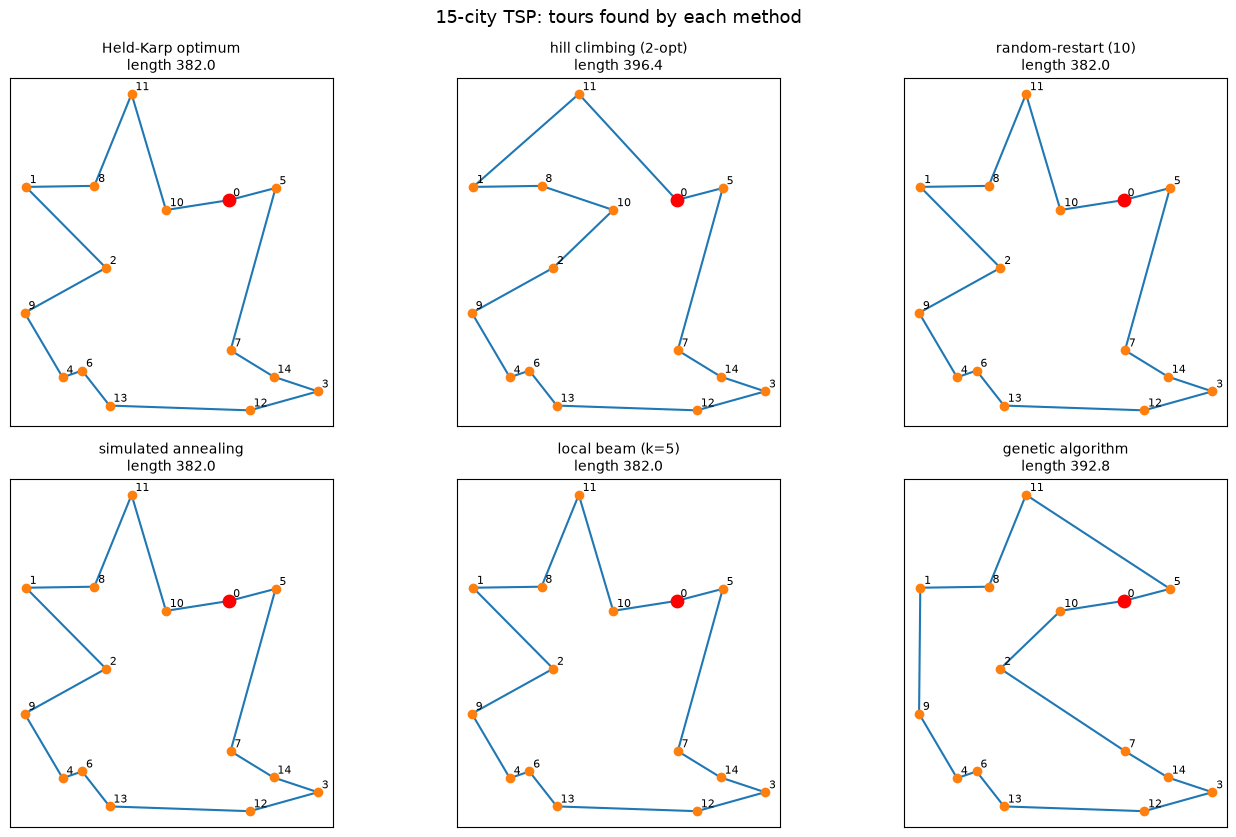

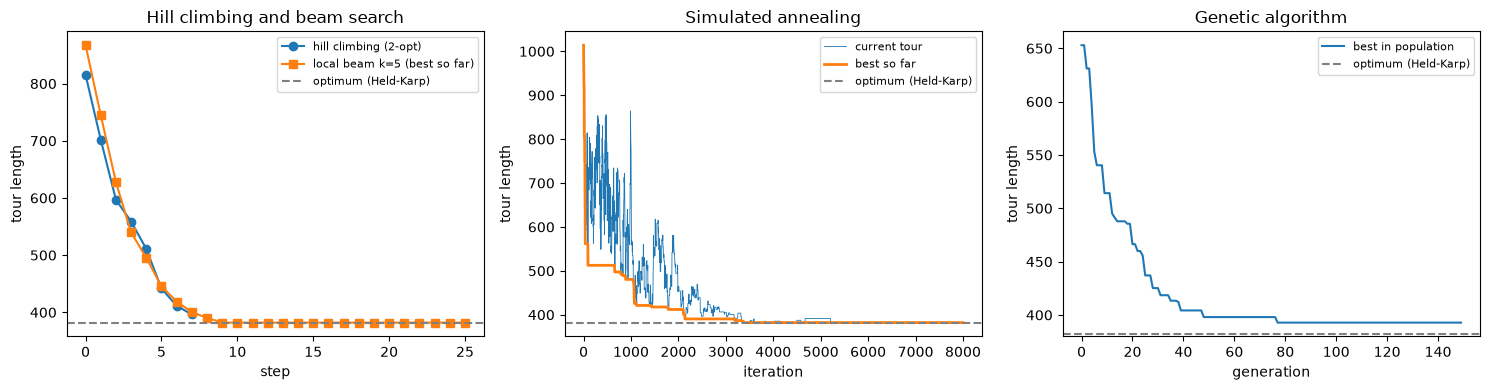

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, (name, t) in zip(axes.ravel(), tours.items()):
    pts = cities[list(t) + [t[0]]]                                 # close the loop
    ax.plot(pts[:, 0], pts[:, 1], "-", color="tab:blue", lw=1.5)
    ax.scatter(cities[:, 0], cities[:, 1], color="tab:orange", zorder=3)
    ax.scatter(*cities[0], color="red", s=80, zorder=4, label="start city 0")
    for i, (x, y) in enumerate(cities):
        ax.text(x + 1.2, y + 1.2, str(i), fontsize=8)
    ax.set_title(f"{name}\nlength {tour_length(t):.1f}", fontsize=10)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("15-city TSP: tours found by each method", fontsize=13)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(hc_trace, "o-", label="hill climbing (2-opt)")
axes[0].plot(beam_trace, "s-", label="local beam k=5 (best so far)")
axes[0].set_xlabel("step"); axes[0].set_title("Hill climbing and beam search")
axes[1].plot(sa_cur, lw=0.6, label="current tour"); axes[1].plot(sa_best, lw=2, label="best so far")
axes[1].set_xlabel("iteration"); axes[1].set_title("Simulated annealing")
axes[2].plot(ga_trace, label="best in population")
axes[2].set_xlabel("generation"); axes[2].set_title("Genetic algorithm")
for ax in axes:
    ax.axhline(OPT, color="gray", ls="--", label="optimum (Held-Karp)")
    ax.set_ylabel("tour length"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What just happened?**
- Single 2-opt **hill climbing** improves very fast (a few dozen steps), then stops at a **2-opt local optimum**: no single segment reversal helps any more.
- **Simulated annealing**'s current tour jumps up and down a lot while the temperature is high, then settles; the "best so far" line is what we keep.
- The **GA**'s best tour improves in steps as good sub-routes spread through the population.
- All tours are checked: each visits every city once, and none is shorter than the Held-Karp optimum (which would indicate a bug).

A single run can be lucky or unlucky, so let us repeat each method with 10 different seeds.

In [21]:
tsp_rows = []
for name, solver in [
    ("hill climbing (2-opt)", lambda rng: tsp_hill_climb(random_tour(rng))[0]),
    ("random-restart (10)", lambda rng: tsp_random_restart(rng)),
    ("simulated annealing", lambda rng: tsp_sa(rng)[0]),
    ("local beam (k=5)", lambda rng: tsp_beam(rng)[0]),
    ("genetic algorithm", lambda rng: tsp_ga(rng)[0]),
]:
    lengths, ms = [], []
    for seed in range(10):
        t0 = time.perf_counter()
        t = solver(random.Random(1000 + seed))
        ms.append(1000 * (time.perf_counter() - t0)); lengths.append(tour_length(t))
    lengths = np.array(lengths)
    tsp_rows.append({"algorithm": name, "runs": 10,
                     "mean % above optimum": max(0.0, round(100 * (lengths.mean() / OPT - 1), 2)),
                     "worst % above optimum": max(0.0, round(100 * (lengths.max() / OPT - 1), 2)),
                     "found optimum (runs)": int((lengths <= OPT + 1e-6).sum()),
                     "mean ms per run": round(float(np.mean(ms)), 1)})
tsp_table = pd.DataFrame(tsp_rows).set_index("algorithm")
display(tsp_table)

,runs,mean % above optimum,worst % above optimum,found optimum (runs),mean ms per run
algorithm,,,,,
hill climbing (2-opt),10,1.61,3.75,5,5.9
random-restart (10),10,0.00,0.00,10,59.1
simulated annealing,10,0.33,1.24,7,110.7
local beam (k=5),10,0.28,2.82,9,90.1
genetic algorithm,10,0.37,1.24,7,328.4


**What just happened?** A single 2-opt hill climb found the optimum in only 5 of 10 runs and was up to 3.75% above it. Random-restart (10 climbs) found the optimum in all 10 runs, local beam search in 9, simulated annealing and the GA in 7, and none of them was more than 3% above. On 15 cities, cheap restarts are hard to beat; the more elaborate methods pay off on larger, harder instances. On real instances with thousands of cities, practical solvers combine these ideas (for example Lin-Kernighan heuristics with restarts, as in the LKH solver).

## 9. Gradient descent: local search in continuous spaces

*In plain words: when answers are real numbers, the slope tells you which way is uphill.*

When the state is a vector of real numbers $\mathbf{x} \in \mathbb{R}^d$, there are infinitely many neighbours, so we cannot list them. But if the objective $f$ is differentiable, the **gradient** $\nabla f(\mathbf{x})$ points in the steepest uphill direction. **Gradient ascent** is steepest-ascent hill climbing with an infinitesimal neighbourhood:

$$\mathbf{x} \leftarrow \mathbf{x} + \alpha \, \nabla f(\mathbf{x}) \qquad \text{(gradient ascent; use } - \text{ for gradient descent on a loss)}$$

where $\alpha$ is the **step size** (learning rate). It has the same weakness as hill climbing: it converges to whatever local optimum (or saddle point) is uphill of the start. Too large an $\alpha$ overshoots; too small crawls.

The full story (convexity, momentum, Adam, learning-rate schedules, Newton's method) is in [`14_Mathematics/06_optimization.ipynb`](../../14_Mathematics/06_optimization.ipynb) and [`05_Deep_Learning/02_optimizers.ipynb`](../../05_Deep_Learning/02_optimizers.ipynb). **Stochastic gradient descent** adds noise from mini-batches, which plays a role a little like the random moves of simulated annealing.

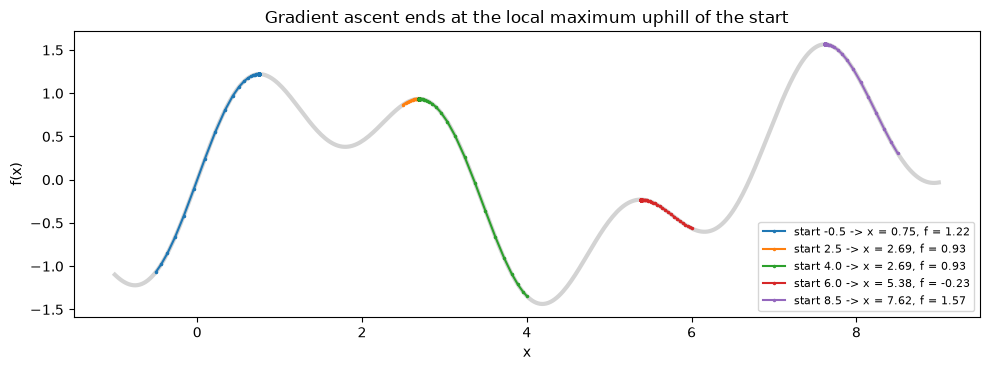

In [22]:
f_c = lambda x: np.sin(x) + 0.6 * np.sin(2.7 * x)                 # a bumpy 1-D objective
df_c = lambda x: np.cos(x) + 0.6 * 2.7 * np.cos(2.7 * x)          # its derivative

def gradient_ascent(x, alpha=0.05, steps=200):
    path = [x]
    for _ in range(steps):
        x = x + alpha * df_c(x)                                   # move uphill along the gradient
        path.append(x)
    return np.array(path)

xs = np.linspace(-1, 9, 400)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(xs, f_c(xs), color="lightgray", lw=3)
for x0 in [-0.5, 2.5, 4.0, 6.0, 8.5]:
    p = gradient_ascent(x0)
    ax.plot(p, f_c(p), ".-", ms=3, label=f"start {x0} -> x = {p[-1]:.2f}, f = {f_c(p[-1]):.2f}")
    assert abs(df_c(p[-1])) < 1e-3                                # converged to a stationary point
ax.set_xlabel("x"); ax.set_ylabel("f(x)"); ax.set_title("Gradient ascent ends at the local maximum uphill of the start")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**What just happened?** Different starting points converge to different local maxima (the derivative at each end point is essentially zero). Gradient methods are *local search*, and the same tricks apply: random restarts, noise, momentum.

> 🎓 **Exam / interview tip:** "Why does gradient descent work so well for deep learning if it is just local search?" In very high dimensions, most stationary points are **saddle points** rather than bad local minima, noise from SGD helps escape them, and many different minima generalise about equally well.

## 10. Summary table

*In plain words: all the methods side by side.*

| Algorithm | States kept | Complete? | Optimal? | Escapes local optima by | Typical use |
|---|---|---|---|---|---|
| Steepest-ascent hill climbing | 1 | No | No | nothing | quick polishing step |
| + sideways moves | 1 | No | No | walking along plateaus | problems with shoulders |
| First-choice hill climbing | 1 | No | No | nothing | huge neighbourhoods |
| Stochastic hill climbing | 1 | No | No | random uphill choices | variety of paths |
| Random-restart hill climbing | 1 | with probability → 1 | with probability → 1 (finite space) | restarting | cheap, strong baseline |
| Simulated annealing | 1 | with probability → 1 (very slow schedule) | same | accepting worse moves | VLSI layout, scheduling |
| Tabu search | 1 + tabu list | No | No | forbidding recent moves | vehicle routing, scheduling |
| Local beam search | $k$ | No | No | sharing $k$ candidates | small beams of good states |
| Stochastic beam search | $k$ | No | No | random survival | keeping diversity |
| Genetic algorithm | population $P$ | No | No | crossover + mutation | design, evolving programs |
| Gradient descent | 1 | No | Only for convex $f$ | (with SGD) noise, momentum | training neural networks |

*Time complexity* is governed by the step budget you choose: each step costs $O(b \cdot e)$ for $b$ neighbours evaluated at cost $e$ (steepest-ascent, beam search with $k b$), or $O(e)$ for one random neighbour (first-choice, annealing), or $O(P \cdot e)$ per GA generation. *Space* is the number of states kept.

## 🔗 How this connects to modern AI

- **LLM decoding:** beam search (Section 5) is a standard decoding option in translation and summarisation models; sampling with temperature is the "stochastic" cousin. See [`07_NLP/05_language_models_and_generation.ipynb`](../../07_NLP/05_language_models_and_generation.ipynb) and [`08_LLM/13_inference_optimization.ipynb`](../../08_LLM/13_inference_optimization.ipynb).
- **Training neural networks** is local search in a space with millions or billions of dimensions, using gradients: [`05_Deep_Learning/02_optimizers.ipynb`](../../05_Deep_Learning/02_optimizers.ipynb).
- **Hyperparameter tuning** often uses random search, evolutionary methods and Bayesian optimisation: [`03_Machine_Learning/06_model_evaluation/02_hyperparameter_optimization.ipynb`](../../03_Machine_Learning/06_model_evaluation/02_hyperparameter_optimization.ipynb).
- **Evolutionary methods** are used for neural architecture search, for evolution strategies in reinforcement learning, and in recent systems where an LLM proposes "mutations" of programs and an evaluator selects the fittest (for example DeepMind's FunSearch, 2023, and AlphaEvolve, 2025).
- **Operations research:** delivery-route planning, chip placement and staff rostering in industry still rely heavily on local search (2-opt, simulated annealing, tabu search), often inside commercial or open-source solvers.

## Recap

- Local search keeps one (or a few) **complete** states and moves to **neighbours**. Memory is tiny, but it is usually neither complete nor optimal.
- The **landscape** has local maxima, plateaus, shoulders and ridges; steepest-ascent hill climbing stops at all of them.
- **Sideways moves** escape shoulders; **random restarts** make hill climbing complete with probability approaching 1 (expected $1/p$ runs).
- **Simulated annealing** accepts a worse move with probability $e^{\Delta E/T}$; high $T$ explores, low $T$ exploits.
- **Local beam search** keeps the best $k$ of all successors; **stochastic beam search** samples them; LLM beam search applies the same "keep the best $k$" idea to partial sequences.
- **Genetic algorithms** = encoding + fitness + selection + crossover + mutation.
- On 8-queens, plain steepest ascent solves only a small fraction of boards; escape mechanisms solve nearly all. On a 15-city TSP, the exact Held-Karp optimum lets us measure how close each heuristic gets.
- **Gradient descent** is hill climbing in continuous space; **tabu search** forbids undoing recent moves.

## Practice problems

**1. (Easy, conceptual)** How many neighbours does a state of the N-Queens complete-state formulation have, and how many states are there in total? Give both for $N = 8$.

<details><summary>Show solution</summary>

Each of the $N$ queens can move to $N - 1$ other rows in its column: $N(N-1)$ neighbours, so 56 for $N = 8$. There are $N^N$ states (each column independently chooses a row): $8^8 = 16{,}777{,}216$.
</details>

**2. (Easy, numeric)** Simulated annealing is at temperature $T = 2$ and proposes a move with $\Delta E = -4$. What is the probability it is accepted? What if $T = 0.5$?

<details><summary>Show solution</summary>

$e^{-4/2} = e^{-2} \approx 0.135$. At $T = 0.5$: $e^{-8} \approx 0.000335$. Colder means far fewer bad moves are accepted.

```python
import math
print(math.exp(-4 / 2), math.exp(-4 / 0.5))   # 0.1353..., 0.000335...
```
</details>

**3. (Medium, conceptual)** Steepest-ascent hill climbing solves 8-queens with probability $p \approx 0.14$, taking about 4 steps on success and 3 on failure. Estimate the expected total number of steps for random-restart hill climbing.

<details><summary>Show solution</summary>

The number of attempts is geometric with mean $1/p \approx 7.1$, so on average there are $(1-p)/p \approx 6.1$ failures and 1 success: $6.1 \times 3 + 1 \times 4 \approx 22$ steps (the figure quoted in AIMA).
</details>

**4. (Medium, conceptual)** Explain why local beam search with $k$ states is *not* the same as running $k$ random restarts in parallel. What problem does this create, and how does stochastic beam search address it?

<details><summary>Show solution</summary>

In local beam search the $k$ states compete in one shared pool: the $k$ best successors of *all* states survive, so one region with good successors can take over every slot. Parallel restarts never share information. The shared pool causes a **loss of diversity** (all $k$ states end up near one local optimum). Stochastic beam search samples survivors with probability that increases with value, so weaker but different states sometimes survive.
</details>

**5. (Medium, coding)** Write `two_opt_delta(tour, i, j, D)` that returns the change in tour length caused by reversing `tour[i:j+1]` *without* recomputing the whole tour, using only four distances. Check it against `tour_length` on random moves.

<details><summary>Show solution</summary>

```python
def two_opt_delta(tour, i, j, D):
    n = len(tour)
    a, b = tour[i - 1], tour[i]            # edge a-b is broken
    c, d = tour[j], tour[(j + 1) % n]      # edge c-d is broken
    return D[a, c] + D[b, d] - D[a, b] - D[c, d]

rng = random.Random(0)
for _ in range(1000):
    t = random_tour(rng)
    i, j = sorted(rng.sample(range(1, N_CITIES), 2))
    new = t[:i] + t[i:j + 1][::-1] + t[j + 1:]
    assert abs(two_opt_delta(t, i, j, D) - (tour_length(new) - tour_length(t))) < 1e-9
print("delta formula verified")
```
Why it works: reversing the segment keeps every internal edge (just traversed backwards); only the two boundary edges change. This makes a 2-opt step $O(1)$ to evaluate instead of $O(n)$.
</details>

**6. (Medium, coding)** Implement **uniform crossover** for 8-queens: each column of the child is copied from parent 1 or parent 2 with probability 1/2. Check that every gene of the child comes from one of the parents.

<details><summary>Show solution</summary>

```python
def uniform_crossover(p1, p2, rng):
    return tuple(a if rng.random() < 0.5 else b for a, b in zip(p1, p2))

rng = random.Random(1)
for _ in range(1000):
    p1, p2 = random_board(8, rng), random_board(8, rng)
    child = uniform_crossover(p1, p2, rng)
    assert all(c in (a, b) for c, a, b in zip(child, p1, p2))
print("uniform crossover OK")
```
</details>

**7. (Hard, conceptual)** Show that simulated annealing with a constant temperature $T \to \infty$ is a random walk, and with $T \to 0$ is first-choice hill climbing (strict improvement only). Which of the two is complete?

<details><summary>Show solution</summary>

As $T \to \infty$, $e^{\Delta E/T} \to 1$ for every $\Delta E$, so every proposed neighbour is accepted: a random walk over the neighbourhood graph. If that graph is connected and finite, the walk eventually visits every state, so it is complete (but very slow). As $T \to 0$, $e^{\Delta E/T} \to 0$ for $\Delta E < 0$ (and the move is accepted only when $\Delta E > 0$), so only strictly better random neighbours are taken: first-choice hill climbing, which can get stuck and is not complete. (Equal moves, $\Delta E = 0$, are accepted with probability $e^0 = 1$ in the textbook rule; our implementation is slightly stricter.)
</details>

**8. (Hard, coding)** Make tabu search for TSP: use the 2-opt neighbourhood, make a reversed pair `(i, j)` tabu for 10 steps, and run 300 steps. How close to the Held-Karp optimum does it get?

<details><summary>Show solution</summary>

```python
def tsp_tabu(rng, tenure=10, steps=300):
    current = random_tour(rng); best = current
    tabu = {}
    for step in range(steps):
        moves = []
        for i in range(1, N_CITIES - 1):
            for j in range(i + 1, N_CITIES):
                t = current[:i] + current[i:j + 1][::-1] + current[j + 1:]
                L = tour_length(t)
                if tabu.get((i, j), -1) < step or L < tour_length(best):   # aspiration
                    moves.append((L, i, j, t))
        L, i, j, current = min(moves)
        tabu[(i, j)] = step + tenure
        if L < tour_length(best):
            best = current
    return best

t = tsp_tabu(random.Random(0))
assert sorted(t) == list(range(N_CITIES))
print(f"tabu tour length {tour_length(t):.2f}, optimum {OPT:.2f}")
```
On this instance it reaches the optimum or within a couple of percent of it.
</details>

## Further reading

- Russell & Norvig, *Artificial Intelligence: A Modern Approach*, 4th ed. (2020), Chapter 4.1 to 4.2 "Search in Complex Environments" (local search, simulated annealing, beam search, genetic algorithms, continuous spaces).
- Kirkpatrick, Gelatt & Vecchi, "Optimization by Simulated Annealing", *Science* 220 (1983).
- Glover & Laguna, *Tabu Search* (1997); Goldberg, *Genetic Algorithms in Search, Optimization and Machine Learning* (1989).
- Free online: the official code repository for AIMA, [aima-python](https://github.com/aimacode/aima-python) (`search.py` contains hill climbing, simulated annealing and genetic algorithms), and the [Concorde TSP solver page](https://www.math.uwaterloo.ca/tsp/) for the state of the art in exact TSP solving.

## Next notebook

[`05_adversarial_search_and_games.ipynb`](05_adversarial_search_and_games.ipynb): what happens when there is an opponent who wants you to lose: minimax, alpha-beta pruning and Monte Carlo Tree Search.

In [23]:
print(f"Notebook finished in {time.time() - NOTEBOOK_START:.1f} s")

Notebook finished in 56.9 s
